# NumCompute-Stream Demo

End to end streaming ML pipeline. We load a CSV using the chunked io pipeline,
train three models incrementally with partial_fit on each chunk, track metrics
as data arrives, and visualise everything using the visualise module.

Dataset: Palmer Penguins (3 species, 4 features, 60 samples)
Models: Decision Tree vs Random Forest vs Bagging

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
from numcompute_stream.io import read_csv_chunked, make_stream_chunks
from numcompute_stream.preprocessing import StandardScaler, Imputer, EMAScaler
from numcompute_stream.stats import RunningStats, MultiFeatureStats, EMAStats
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.ensemble import RandomForestClassifier, BaggingClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.metrics import (
    AccuracyTracker, ConfusionMatrixTracker, StreamingAUC, RollingAccuracy
)
import numcompute_stream.visualise as vis

print('all imports ok')

all imports ok


## 1. Load dataset using the chunked CSV pipeline

read_csv_chunked is a generator that yields one chunk at a time straight
from disk. This is how the io pipeline is meant to be used in a real
streaming scenario where you would not load the whole file at once.

In [2]:
CHUNK_SIZE = 10
CSV_PATH = 'penguins.csv'

# first pass: collect all chunks so we can inspect them and reuse for multiple models
all_chunks_raw = []
headers = None
for hdrs, chunk_data in read_csv_chunked(CSV_PATH, chunk_size=CHUNK_SIZE):
    if headers is None:
        headers = hdrs
    all_chunks_raw.append(chunk_data)

print(f'headers: {headers}')
print(f'loaded {len(all_chunks_raw)} chunks of up to {CHUNK_SIZE} rows each')
print(f'total rows: {sum(c.shape[0] for c in all_chunks_raw)}')
print(f'features: {headers[:-1]}')
print(f'label column: {headers[-1]}')

# split features and labels
chunks = [(c[:, :-1], c[:, -1].astype(int)) for c in all_chunks_raw]

for i, (xc, yc) in enumerate(chunks):
    print(f'  chunk {i+1}: {xc.shape[0]} samples, classes present: {np.unique(yc).tolist()}')

headers: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species']
loaded 6 chunks of up to 10 rows each
total rows: 60
features: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
label column: species
  chunk 1: 10 samples, classes present: [0]
  chunk 2: 10 samples, classes present: [0]
  chunk 3: 10 samples, classes present: [1]
  chunk 4: 10 samples, classes present: [1]
  chunk 5: 10 samples, classes present: [2]
  chunk 6: 10 samples, classes present: [2]


## 2. Incremental data statistics before training

Before fitting any model, run the raw feature data through MultiFeatureStats
and EMAStats to see what the stream looks like statistically as chunks arrive.

In [3]:
from numcompute_stream.stats import MultiFeatureStats, EMAStats

mfs = MultiFeatureStats()
ema = EMAStats(alpha=0.3)

for X_chunk, _ in chunks:
    mfs.update_stats(X_chunk)
    # track EMA on first feature as an example
    ema.update_stats(X_chunk[:, 0])

stats_result = mfs.result()
print('running means per feature:', np.round(stats_result['means'], 3))
print('running stds per feature: ', np.round(stats_result['stds'], 3))
print()
print('EMA stats on feature 0 (culmen_length_mm):')
print(ema.result())

running means per feature: [  41.52    17.422  198.55  4171.668]
running stds per feature:  [  4.606   2.187  13.071 727.932]

EMA stats on feature 0 (culmen_length_mm):
{'mean': 42.935588900000006, 'variance': 22.788236740196787, 'std': 4.773702623770859, 'alpha': 0.3}


## 3. Set up three pipelines for comparison

In [4]:
def make_pipeline(model):
    return Pipeline([
        ('impute', Imputer(strategy='mean')),
        ('scale', StandardScaler()),
        ('model', model),
    ])

pipe_tree = make_pipeline(DecisionTreeClassifier(max_depth=4, random_state=0))
pipe_rf   = make_pipeline(RandomForestClassifier(n_estimators=10, max_depth=4, random_state=0))
pipe_bag  = make_pipeline(BaggingClassifier(n_estimators=10, max_depth=4, random_state=0))

trainer_tree = StreamTrainer(pipe_tree, classes=[0, 1, 2])
trainer_rf   = StreamTrainer(pipe_rf,   classes=[0, 1, 2])
trainer_bag  = StreamTrainer(pipe_bag,  classes=[0, 1, 2])

print('three pipelines ready')
print('  Decision Tree  -> Imputer -> StandardScaler -> DecisionTreeClassifier(depth=4)')
print('  Random Forest  -> Imputer -> StandardScaler -> RandomForestClassifier(10 trees)')
print('  Bagging        -> Imputer -> StandardScaler -> BaggingClassifier(10 trees)')

three pipelines ready
  Decision Tree  -> Imputer -> StandardScaler -> DecisionTreeClassifier(depth=4)
  Random Forest  -> Imputer -> StandardScaler -> RandomForestClassifier(10 trees)
  Bagging        -> Imputer -> StandardScaler -> BaggingClassifier(10 trees)


## 4. Train incrementally chunk by chunk

Each call to fit_chunk runs partial_fit on the whole pipeline, scores
on the same chunk, and logs accuracy, loss, timing, and memory usage.

In [5]:
for X_chunk, y_chunk in chunks:
    trainer_tree.fit_chunk(X_chunk, y_chunk)
    trainer_rf.fit_chunk(X_chunk, y_chunk)
    trainer_bag.fit_chunk(X_chunk, y_chunk)

print('training complete')
print()
print('--- Decision Tree ---')
trainer_tree.summary()
print()
print('--- Random Forest ---')
trainer_rf.summary()

training complete

--- Decision Tree ---
 chunk   samples       acc   cum_acc      loss    time_s    mem_kb
----------------------------------------------------------------------
     1        10    1.0000    1.0000    0.0000    0.0002         0
     2        10    1.0000    1.0000    0.0000    0.0001         0
     3        10    0.6000    0.8667    0.4000    0.0035         0
     4        10    0.8000    0.8500    0.2000    0.0035         1
     5        10    1.0000    0.8800    0.0000    0.0042         1
     6        10    1.0000    0.9000    0.0000    0.0050         1
----------------------------------------------------------------------
final cumulative accuracy: 0.9000

--- Random Forest ---
 chunk   samples       acc   cum_acc      loss    time_s    mem_kb
----------------------------------------------------------------------
     1        10    1.0000    1.0000    0.0000    0.0006         0
     2        10    1.0000    1.0000    0.0000    0.0006         0
     3        10   

## 5. Accuracy over time

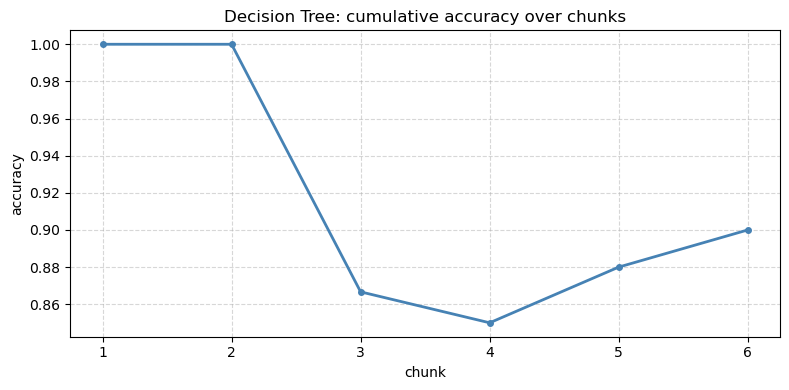

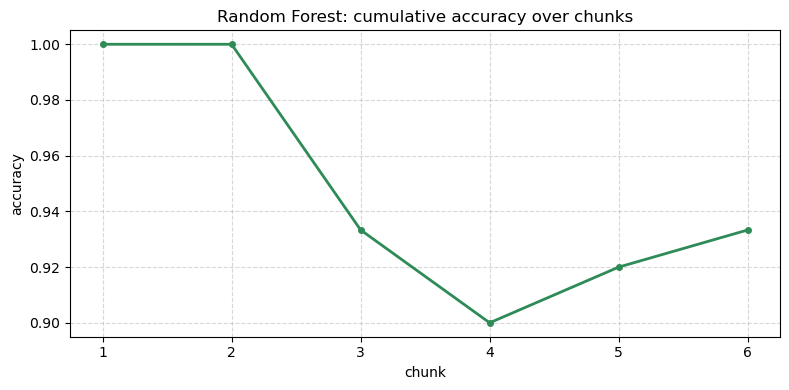

<Axes: title={'center': 'Random Forest: cumulative accuracy over chunks'}, xlabel='chunk', ylabel='accuracy'>

In [6]:
vis.plot_metric_over_time(
    trainer_tree.cumulative_accuracy_history(),
    title='Decision Tree: cumulative accuracy over chunks',
    ylabel='accuracy'
)

vis.plot_metric_over_time(
    trainer_rf.cumulative_accuracy_history(),
    title='Random Forest: cumulative accuracy over chunks',
    ylabel='accuracy',
    color='seagreen'
)

## 6. Model comparison: Random Forest vs Bagging

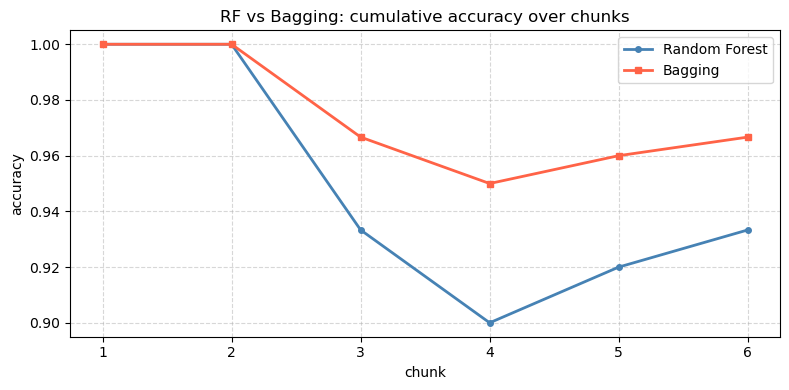

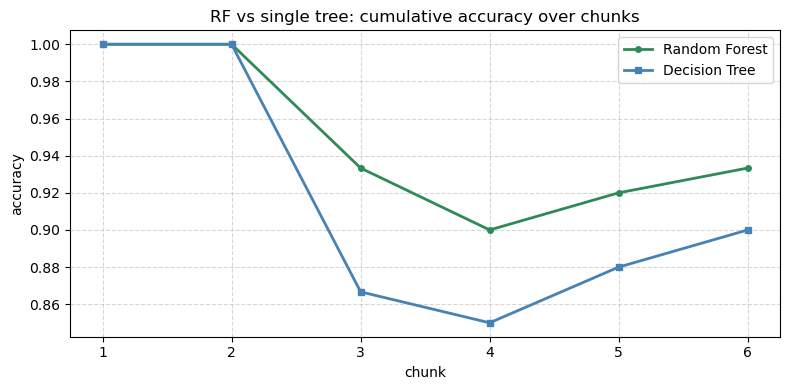

<Axes: title={'center': 'RF vs single tree: cumulative accuracy over chunks'}, xlabel='chunk', ylabel='accuracy'>

In [7]:
vis.compare_models(
    trainer_rf.cumulative_accuracy_history(),
    trainer_bag.cumulative_accuracy_history(),
    labels=('Random Forest', 'Bagging'),
    title='RF vs Bagging: cumulative accuracy over chunks',
    ylabel='accuracy'
)

vis.compare_models(
    trainer_rf.cumulative_accuracy_history(),
    trainer_tree.cumulative_accuracy_history(),
    labels=('Random Forest', 'Decision Tree'),
    title='RF vs single tree: cumulative accuracy over chunks',
    ylabel='accuracy',
    colors=('seagreen', 'steelblue')
)

## 7. Loss over time

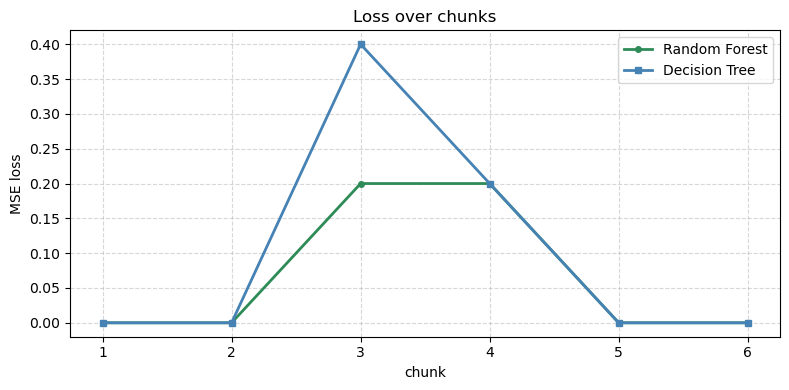

<Axes: title={'center': 'Loss over chunks'}, xlabel='chunk', ylabel='MSE loss'>

In [8]:
vis.compare_models(
    trainer_rf.loss_history(),
    trainer_tree.loss_history(),
    labels=('Random Forest', 'Decision Tree'),
    title='Loss over chunks',
    ylabel='MSE loss',
    colors=('seagreen', 'steelblue')
)

## 8. Predictions vs ground truth on last chunk

last chunk ground truth: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
random forest predicted: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
accuracy on last chunk:  1.000


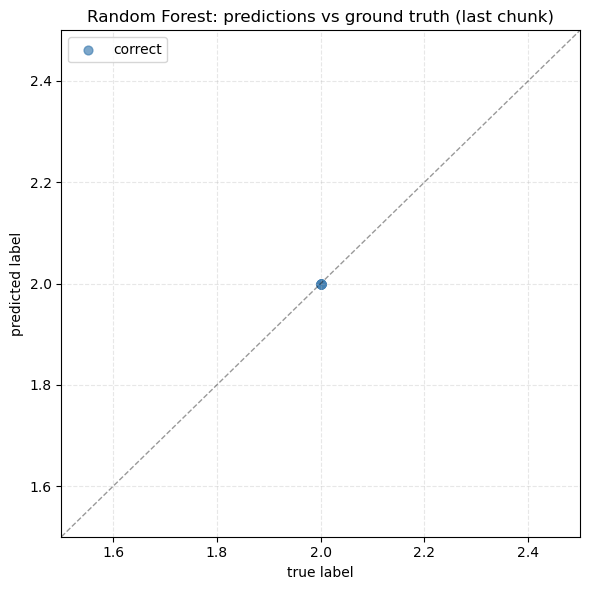

<Axes: title={'center': 'Random Forest: predictions vs ground truth (last chunk)'}, xlabel='true label', ylabel='predicted label'>

In [9]:
X_last, y_last = chunks[-1]
preds_rf = pipe_rf.predict(X_last)

print(f'last chunk ground truth: {y_last.tolist()}')
print(f'random forest predicted: {preds_rf.tolist()}')
print(f'accuracy on last chunk:  {np.mean(preds_rf == y_last):.3f}')

vis.plot_predictions_vs_ground_truth(
    y_last,
    preds_rf,
    title='Random Forest: predictions vs ground truth (last chunk)'
)

## 9. Confusion matrix on full dataset

Random Forest  overall accuracy: 0.733
Decision Tree  overall accuracy: 0.733


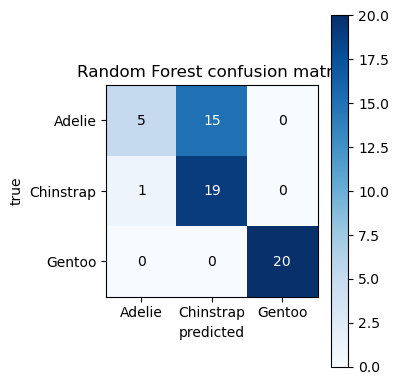

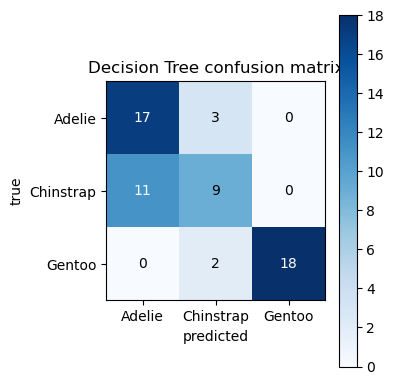

<Axes: title={'center': 'Decision Tree confusion matrix'}, xlabel='predicted', ylabel='true'>

In [10]:
X_all = np.vstack([xc for xc, _ in chunks])
y_all = np.concatenate([yc for _, yc in chunks])

preds_all_rf   = pipe_rf.predict(X_all)
preds_all_tree = pipe_tree.predict(X_all)

cmt_rf = ConfusionMatrixTracker()
cmt_rf.update(y_all, preds_all_rf)

cmt_tree = ConfusionMatrixTracker()
cmt_tree.update(y_all, preds_all_tree)

print(f'Random Forest  overall accuracy: {np.mean(preds_all_rf == y_all):.3f}')
print(f'Decision Tree  overall accuracy: {np.mean(preds_all_tree == y_all):.3f}')

vis.plot_confusion_matrix(
    cmt_rf.result()['matrix'],
    classes=['Adelie', 'Chinstrap', 'Gentoo'],
    title='Random Forest confusion matrix'
)

vis.plot_confusion_matrix(
    cmt_tree.result()['matrix'],
    classes=['Adelie', 'Chinstrap', 'Gentoo'],
    title='Decision Tree confusion matrix'
)

## 10. Streaming AUC for binary sub-problem

AUC is defined for binary classification. We run it on a
Gentoo vs non-Gentoo sub-problem (class 2 vs rest) since
Gentoo is the most separable of the three species.

streaming AUC after all chunks: 1.0000


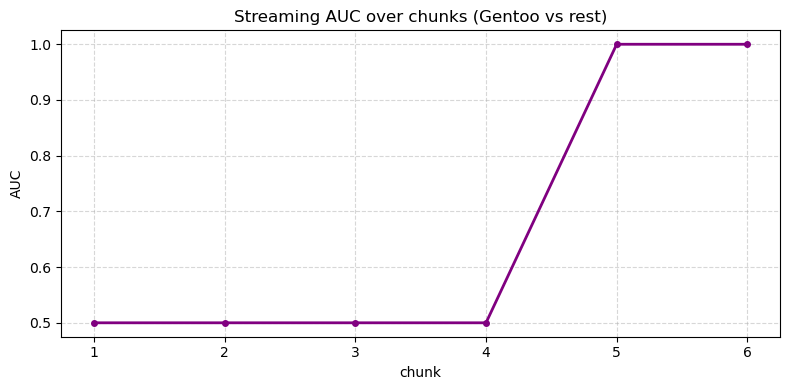

<Axes: title={'center': 'Streaming AUC over chunks (Gentoo vs rest)'}, xlabel='chunk', ylabel='AUC'>

In [11]:
# binary pipeline: Gentoo (2) vs rest (0)
binary_chunks = []
for X_chunk, y_chunk in chunks:
    y_bin = (y_chunk == 2).astype(int)
    binary_chunks.append((X_chunk, y_bin))

pipe_binary = Pipeline([
    ('impute', Imputer(strategy='mean')),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=10, max_depth=4, random_state=0)),
])

auc_tracker = StreamingAUC()

for X_chunk, y_bin_chunk in binary_chunks:
    pipe_binary.partial_fit(X_chunk, y_bin_chunk, classes=[0, 1])
    proba = pipe_binary.predict_proba(X_chunk)
    # use probability of positive class (Gentoo)
    scores = proba[:, 1] if proba.shape[1] > 1 else proba[:, 0]
    auc_tracker.update(y_bin_chunk, scores, pos_label=1)

print(f'streaming AUC after all chunks: {auc_tracker.result():.4f}')

vis.plot_metric_over_time(
    auc_tracker.history,
    title='Streaming AUC over chunks (Gentoo vs rest)',
    ylabel='AUC',
    color='purple'
)

## 11. Rolling accuracy window

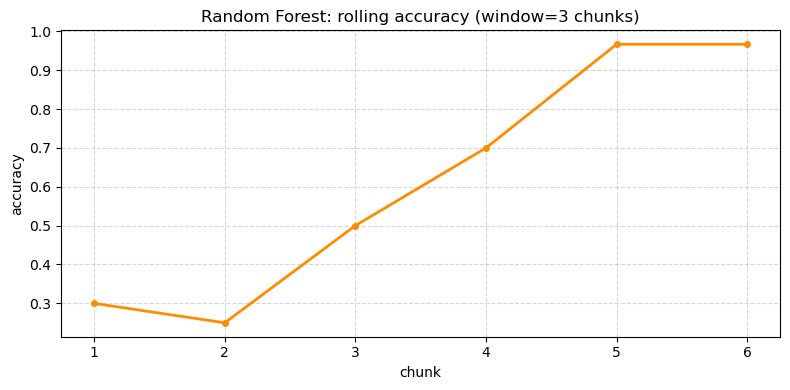

<Axes: title={'center': 'Random Forest: rolling accuracy (window=3 chunks)'}, xlabel='chunk', ylabel='accuracy'>

In [12]:
rolling = RollingAccuracy(window=3)
for X_chunk, y_chunk in chunks:
    preds = pipe_rf.predict(X_chunk)
    rolling.update(y_chunk, preds)

vis.plot_metric_over_time(
    rolling.history,
    title='Random Forest: rolling accuracy (window=3 chunks)',
    ylabel='accuracy',
    color='darkorange'
)

## 12. Memory footprint as buffer grows

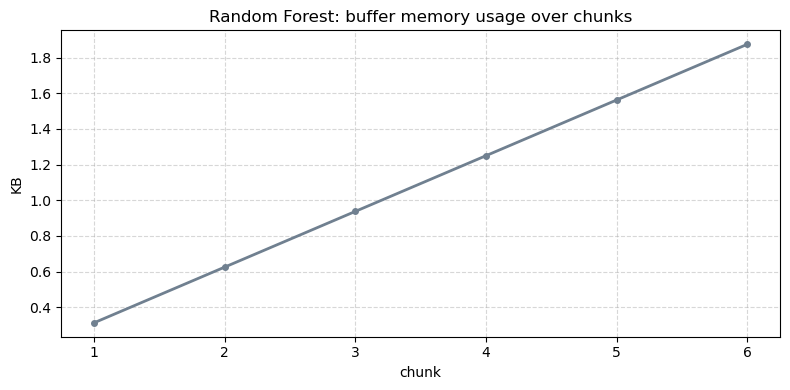

memory footprint per chunk (KB):
  chunk 1: 0.31 KB
  chunk 2: 0.62 KB
  chunk 3: 0.94 KB
  chunk 4: 1.25 KB
  chunk 5: 1.56 KB
  chunk 6: 1.88 KB


In [13]:
mem_kb = [b / 1024 for b in trainer_rf.memory_history()]
vis.plot_metric_over_time(
    mem_kb,
    title='Random Forest: buffer memory usage over chunks',
    ylabel='KB',
    color='slategray'
)

print('memory footprint per chunk (KB):')
for i, kb in enumerate(mem_kb):
    print(f'  chunk {i+1}: {kb:.2f} KB')

## 13. Training time per chunk

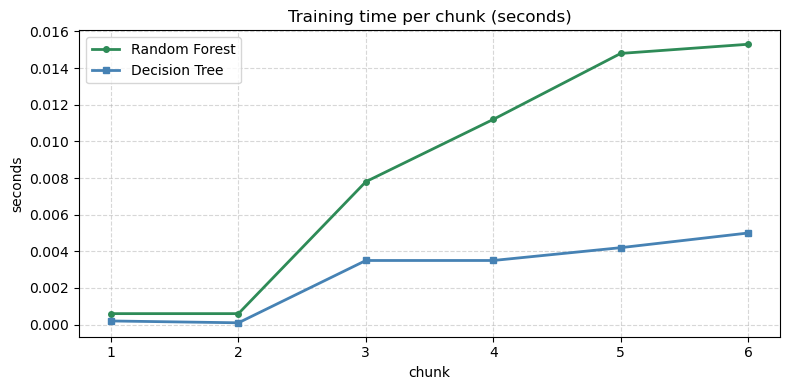

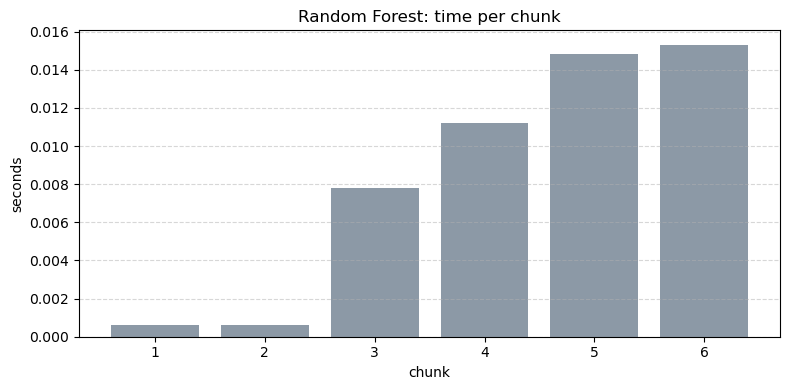

<Axes: title={'center': 'Random Forest: time per chunk'}, xlabel='chunk', ylabel='seconds'>

In [14]:
elapsed_rf   = [e['elapsed_s'] for e in trainer_rf.chunk_log]
elapsed_tree = [e['elapsed_s'] for e in trainer_tree.chunk_log]

vis.compare_models(
    elapsed_rf,
    elapsed_tree,
    labels=('Random Forest', 'Decision Tree'),
    title='Training time per chunk (seconds)',
    ylabel='seconds',
    colors=('seagreen', 'steelblue')
)

vis.plot_chunk_times(elapsed_rf, title='Random Forest: time per chunk')

## 14. EMA Scaler demonstration

Shows the difference between StandardScaler (equal weight to all past data)
and EMAScaler (more weight to recent chunks, adapts to distribution shift).

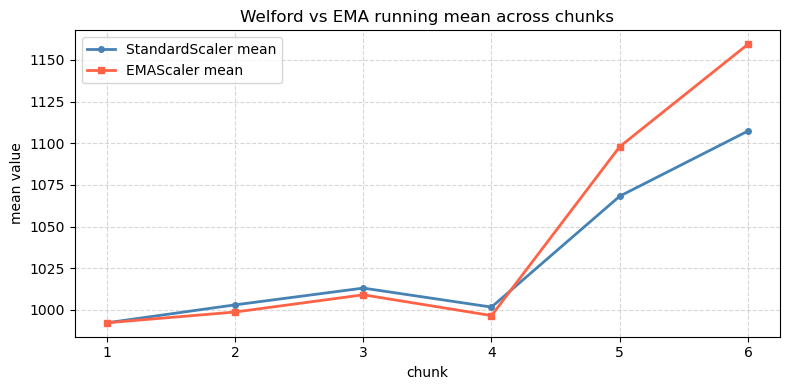

final StandardScaler means: [  41.52    17.422  198.55  4171.668]
final EMAScaler means:      [  42.936   16.673  202.834 4375.013]


In [15]:
std_scaler = StandardScaler()
ema_scaler = EMAScaler(alpha=0.3)

std_means = []
ema_means = []

for X_chunk, _ in chunks:
    std_scaler.partial_fit(X_chunk)
    ema_scaler.partial_fit(X_chunk)
    std_means.append(float(np.mean([t.mean_ for t in std_scaler.trackers])))
    ema_means.append(float(np.mean(ema_scaler.mean_)))

vis.compare_models(
    std_means,
    ema_means,
    labels=('StandardScaler mean', 'EMAScaler mean'),
    title='Welford vs EMA running mean across chunks',
    ylabel='mean value',
    colors=('steelblue', 'tomato')
)

print('final StandardScaler means:', np.round([t.mean_ for t in std_scaler.trackers], 3))
print('final EMAScaler means:     ', np.round(ema_scaler.mean_, 3))